# 02 · Baseline — CNN from scratch (Keras, CPU)

**Goal:** have a simple reference point before using transfer learning. The model in notebook 03 is compared against the results of this one.

**Decisions (made from the EDA):**
- Main metric: **macro F1**, because there is an imbalance of ~36x between classes.
- `Background_without_leaves` is kept as a class and metrics without it are also reported.
- Training **with and without `class_weight`** (weights that give more importance to classes with fewer images) is compared, with one run for each case.
- Images reduced to 128x128 and training on 25% of train, in order to train on CPU in a reasonable amount of time.

## 1. Setup

The libraries are imported, the seed (42) is set so that the results are reproducible, and the data function from `src/data.py` is loaded. If TensorFlow reports that it is not using a GPU, that is expected: all training runs on CPU.

In [9]:
import os
import sys
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from src.data import load_splits, to_arrays

SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams["figure.dpi"] = 110
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Experiment configuration

- `IMG_SIZE`, `BATCH`, and `EPOCHS`: input size (128x128, smaller than the one used in transfer learning to save compute), batch size, and maximum number of epochs.
- `USE_SUBSET` and `SUBSET_FRACTION`: with `USE_SUBSET=True`, training uses a stratified fraction of train (25%, about 9,700 images). This is the configuration of the reported results and the one notebook 03 uses for comparison.
- `USE_CLASS_WEIGHT`: turns balanced class weights on or off. One run was made with each value.
- `EXP_NAME`: experiment name; it defines the files saved in `models/` and `reports/`.

In [10]:
IMG_SIZE = (128, 128)      # (width, height)
BATCH = 32
EPOCHS = 15

USE_SUBSET = True          # True: uses a stratified fraction of train
SUBSET_FRACTION = 0.25
USE_CLASS_WEIGHT = False   # True: applies balanced class weights

EXP_NAME = (
    f"baseline_{'cw' if USE_CLASS_WEIGHT else 'nocw'}_{IMG_SIZE[0]}"
    + ("_subset" if USE_SUBSET else "_full")
)
print("Experiment:", EXP_NAME)

Experiment: baseline_nocw_128_subset


## 3. Data

The splits from notebook 01 are loaded and the images are converted only once into 128x128 arrays, which are saved in `data/cache/` and read from disk in subsequent runs. Then, if `USE_SUBSET=True`, a stratified sample of 25% of train (9,703 images) is taken, keeping the proportion of each class.

In [11]:
train, val, test = load_splits()

label_feat = train.features["label"]
id2name = dict(enumerate(label_feat.names))
n_classes = len(id2name)
bg_id = [k for k, v in id2name.items() if v.startswith("Background")][0]
print("Classes:", n_classes, "| background class id:", bg_id)

Classes: 39 | background class id: 4


In [12]:
t0 = time.time()
X_train, y_train = to_arrays(train, IMG_SIZE, name="train")
X_val, y_val = to_arrays(val, IMG_SIZE, name="val")
X_test, y_test = to_arrays(test, IMG_SIZE, name="test")
print(f"Listo en {time.time() - t0:.0f} s")
print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

[cache] train_38812_128x128.npz
[cache] val_8317_128x128.npz
[cache] test_8318_128x128.npz
Listo en 9 s
train: (38812, 128, 128, 3) | val: (8317, 128, 128, 3) | test: (8318, 128, 128, 3)


In [13]:
if USE_SUBSET:
    idx = np.arange(len(y_train))
    keep, _ = train_test_split(
        idx, train_size=SUBSET_FRACTION, stratify=y_train, random_state=SEED
    )
    X_train, y_train = X_train[keep], y_train[keep]
    print("Train reduced to:", X_train.shape)

Train reduced to: (9703, 128, 128, 3)


## 4. Class weights

scikit-learn's `balanced` weights are inversely proportional to the frequency of each class: classes with few images weigh more in the loss function (here, between 0.26 and 9.57). They are applied only if `USE_CLASS_WEIGHT=True`.

In [14]:
classes = np.arange(n_classes)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}

print(f"Weights: min={min(weights):.2f}  max={max(weights):.2f}")
cw = class_weight if USE_CLASS_WEIGHT else None
print("Using class_weight:", USE_CLASS_WEIGHT)

Weights: min=0.26  max=9.57
Using class_weight: False


## 5. Model

Small CNN with 4 blocks (Conv → BatchNorm → ReLU → MaxPool, with 16, 32, 64, and 128 filters) followed by `GlobalAveragePooling`, dropout of 0.3, and a dense layer with 39 outputs. It has 103,191 parameters and is designed to be fast on CPU. The augmentation (horizontal and vertical flip, slight rotation, and zoom) is built into the model and is only applied during training.

In [15]:
def build_baseline(input_shape, n_classes):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)

    # Augmentation (solo activo en entrenamiento)
    x = layers.RandomFlip("horizontal_and_vertical")(x)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)

    for filters in (16, 32, 64, 128):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn")

model = build_baseline((IMG_SIZE[1], IMG_SIZE[0], 3), n_classes)
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 103,191 (403.09 KB)

 Trainable params: 102,711 (401.21 KB)

 Non-trainable params: 480 (1.88 KB)

## 6. Training

The Adam optimizer is used (initial learning rate of 1e-3) along with three callbacks: `EarlyStopping` (stops training if `val_loss` does not improve for 4 epochs), `ReduceLROnPlateau` (halves the learning rate if there is no improvement for 2 epochs), and `ModelCheckpoint` (saves the best version according to `val_loss` in `models/`). With 25% of train, each epoch takes about 75 seconds and the full training, between 18 and 20 minutes. In the first epochs the validation is unstable (`val_accuracy` is 0.07 in epoch 1 and 0.56 in epoch 2) and improves as training progresses.

In [16]:
os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
    ),
    keras.callbacks.ModelCheckpoint(
        os.path.join(ROOT, "models", f"{EXP_NAME}.keras"),
        monitor="val_loss", save_best_only=True,
    ),
]

t0 = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH,
    epochs=EPOCHS,
    class_weight=cw,
    callbacks=callbacks,
    shuffle=True,
)
train_time = time.time() - t0
print(f"Total training time: {train_time / 60:.1f} min")

Epoch 1/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 76s 246ms/step - accuracy: 0.4565 - loss: 2.0690 - val_accuracy: 0.0739 - val_loss: 4.8671 - learning_rate: 0.0010
Epoch 2/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 69s 226ms/step - accuracy: 0.6008 - loss: 1.4097 - val_accuracy: 0.5615 - val_loss: 1.4879 - learning_rate: 0.0010
Epoch 3/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 68s 224ms/step - accuracy: 0.6644 - loss: 1.1475 - val_accuracy: 0.4850 - val_loss: 1.8316 - learning_rate: 0.0010
Epoch 4/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 67s 222ms/step - accuracy: 0.7099 - loss: 0.9891 - val_accuracy: 0.5274 - val_loss: 1.6497 - learning_rate: 0.0010
Epoch 5/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 69s 227ms/step - accuracy: 0.7543 - loss: 0.8335 - val_accuracy: 0.6906 - val_loss: 1.0450 - learning_rate: 5.0000e-04
Epoch 6/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 70s 231ms/step - accuracy: 0.7707 - loss: 0.7639 - val_accuracy: 0.6914 - val_loss: 1.0439 - learning_rate: 5.0000e-04
Epoch 7/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 71s 234ms/step - accur

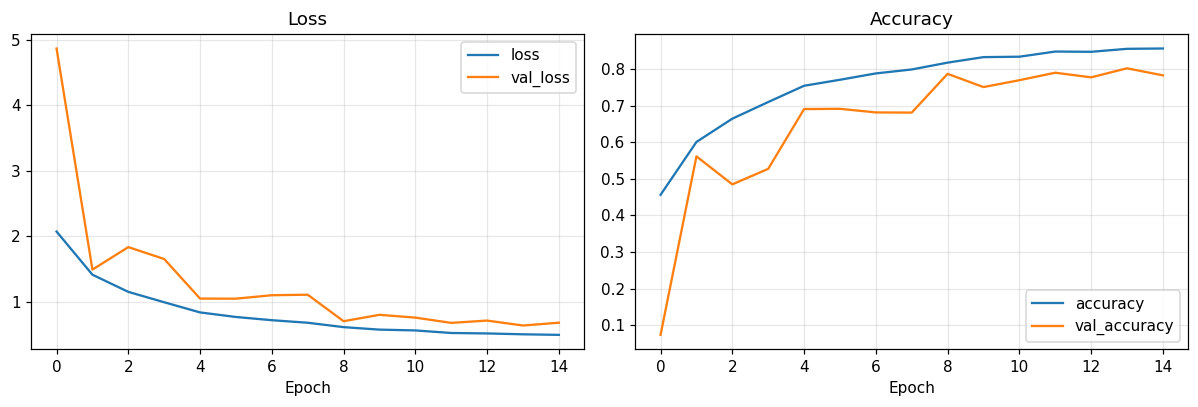

In [17]:
hist = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="Loss")
hist[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Evaluation on test

The test set is used only to measure performance, not to make training decisions. The following are reported:

- **Accuracy:** proportion of correctly classified images.
- **Macro F1:** average of the F1 of each class, giving all of them the same weight; it is the main metric because of the class imbalance.
- **Macro F1 without the background class:** the same average without counting `Background_without_leaves`, to verify that this class does not inflate the result.

Then the table of precision, recall, and F1 per class (from worst to best) and the per-class F1 chart are shown.

In [18]:
probs = model.predict(X_test, batch_size=64, verbose=0)
y_pred = probs.argmax(axis=1)

acc = float((y_pred == y_test).mean())
f1_macro = f1_score(y_test, y_pred, average="macro")
labels_no_bg = [c for c in range(n_classes) if c != bg_id]
f1_macro_no_bg = f1_score(y_test, y_pred, labels=labels_no_bg, average="macro")

print(f"Accuracy:                     {acc:.4f}")
print(f"F1 macro:                     {f1_macro:.4f}")
print(f"F1 macro (with no background):   {f1_macro_no_bg:.4f}")

Accuracy:                     0.8033
F1 macro:                     0.7458
F1 macro (with no background):   0.7426


In [19]:
names = [id2name[i] for i in range(n_classes)]
report = classification_report(
    y_test, y_pred, labels=list(range(n_classes)),
    target_names=names, zero_division=0, output_dict=True,
)
df_rep = pd.DataFrame(report).T.iloc[:n_classes][["precision", "recall", "f1-score", "support"]]
df_rep.sort_values("f1-score").round(3)

,precision,recall,f1-score,support
Tomato___Spider_mites Two-spotted_spider_mite,0.481,0.302,0.371,252.0
Grape___healthy,1.000,0.286,0.444,63.0
Grape___Black_rot,0.581,0.424,0.490,177.0
Potato___Late_blight,0.569,0.493,0.529,150.0
Apple___Cedar_apple_rust,1.000,0.366,0.536,41.0
Tomato___Target_Spot,0.389,0.896,0.542,211.0
Potato___healthy,0.439,0.783,0.562,23.0
Apple___Apple_scab,0.682,0.479,0.562,94.0
Apple___Black_rot,0.408,0.978,0.576,93.0
Tomato___Early_blight,0.512,0.713,0.596,150.0


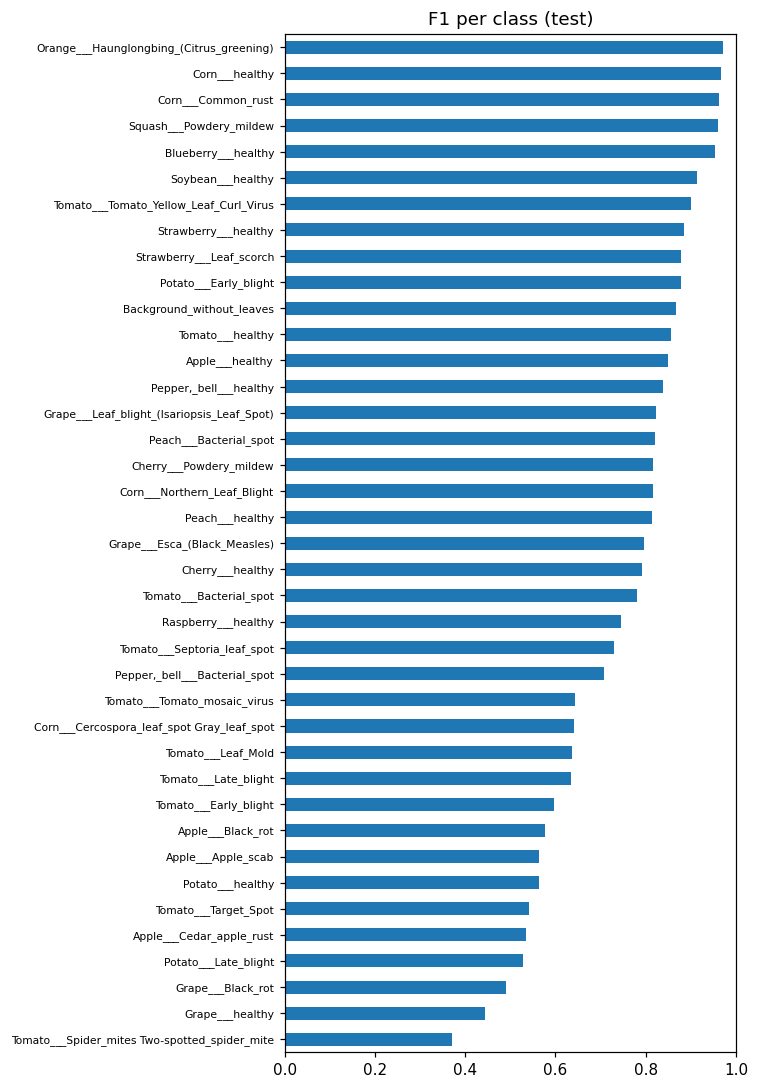

In [20]:
f1_by_class = df_rep["f1-score"].sort_values()
fig, ax = plt.subplots(figsize=(7, 10))
f1_by_class.plot.barh(ax=ax)
ax.set_xlim(0, 1)
ax.set_title("F1 per class (test)")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### 7.1 Confusion matrix

Each row is the true class and each column the predicted class, normalized by row: the diagonal shows the proportion of correct predictions for each class and the off-diagonal values, the errors. Since there are 39 classes, the 10 most frequent confusions are listed below.

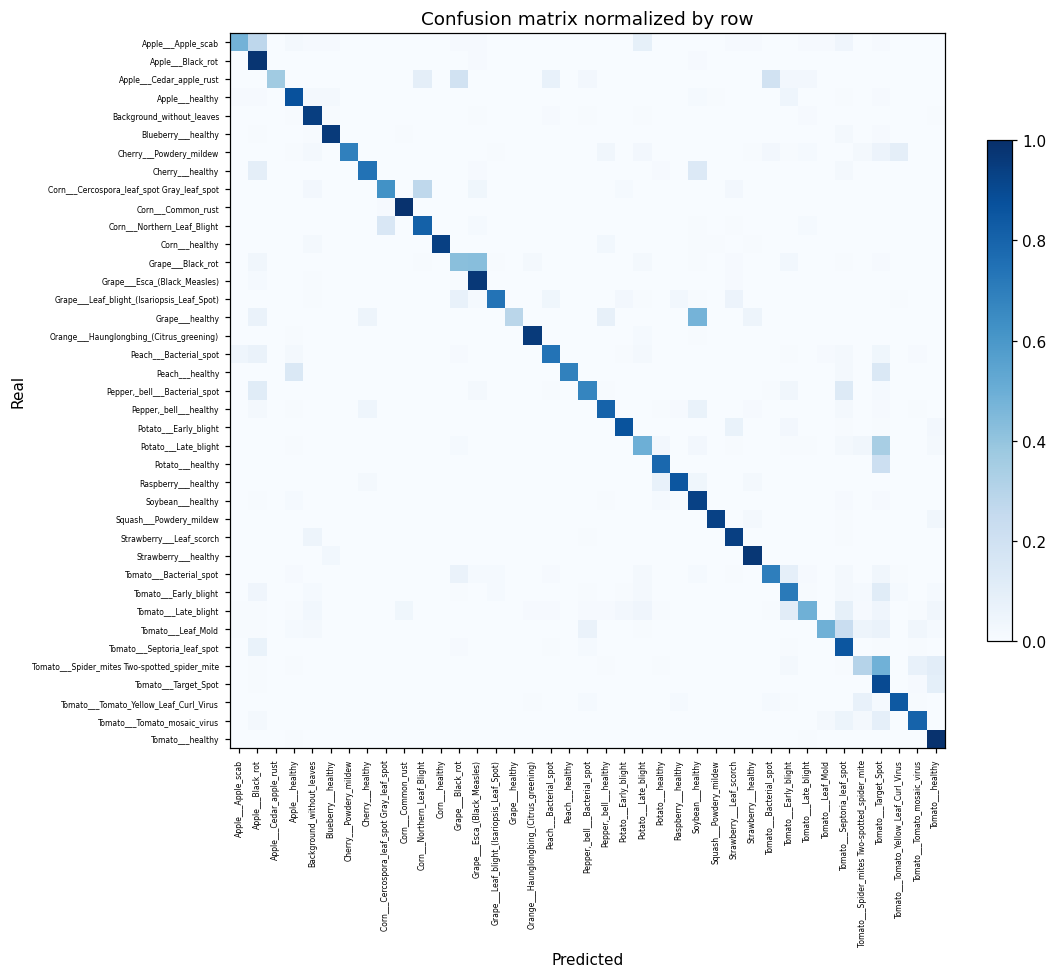

In [21]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(n_classes)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xticklabels(names, rotation=90, fontsize=5)
ax.set_yticklabels(names, fontsize=5)
ax.set_xlabel("Predicted")
ax.set_ylabel("Real")
ax.set_title("Confusion matrix normalized by row")
plt.colorbar(im, fraction=0.03)
plt.tight_layout()
plt.show()

In [22]:
# The most frequent confusions (off the diagonal)
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(off[i, j], names[i], names[j]) for i in range(n_classes) for j in range(n_classes) if off[i, j] > 0]
pairs.sort(reverse=True)

pd.DataFrame(pairs[:10], columns=["number", "real class", "predicted as"])

,number,real class,predicted as
0,123,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot
1,76,Grape___Black_rot,Grape___Esca_(Black_Measles)
2,61,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Spider_mites Two-spotted_spider_mite
3,51,Potato___Late_blight,Tomato___Target_Spot
4,33,Tomato___Leaf_Mold,Tomato___Septoria_leaf_spot
5,32,Tomato___Late_blight,Tomato___Early_blight
6,30,Grape___healthy,Soybean___healthy
7,28,Tomato___Bacterial_spot,Tomato___Early_blight
8,26,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___healthy
9,26,Apple___Apple_scab,Apple___Black_rot


## 8. Save results

The experiment results are saved in a `.json` file inside `reports/`, named after the experiment. The final table brings together the saved training experiments (those from this notebook and those from notebook 03) so they can be compared.

In [25]:
results = {
    "experiment": EXP_NAME,
    "img_size": list(IMG_SIZE),
    "subset": USE_SUBSET,
    "class_weight": USE_CLASS_WEIGHT,
    "run_epochs": int(len(hist)),
    "training_minutes": round(train_time / 60, 1),
    "accuracy": round(acc, 4),
    "f1_macro": round(float(f1_macro), 4),
    "f1_macro_with_no_background": round(float(f1_macro_no_bg), 4),
    "params": int(model.count_params()),
}
out = os.path.join(ROOT, "reports", f"{EXP_NAME}.json")
with open(out, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Saved in", out)
results

Saved in c:\Users\Carlos\Desktop\Python-Prep\proyecto_vision_plantvillage\reports\baseline_nocw_128_subset.json


{'experiment': 'baseline_nocw_128_subset',
 'img_size': [128, 128],
 'subset': True,
 'class_weight': False,
 'run_epochs': 15,
 'training_minutes': 17.6,
 'accuracy': 0.8033,
 'f1_macro': 0.7458,
 'f1_macro_with_no_background': 0.7426,
 'params': 103191}

In [26]:
# Comparison table of the training experiments saved in reports/
rows = []
for fn in sorted(os.listdir(os.path.join(ROOT, "reports"))):
    if fn.endswith(".json"):
        with open(os.path.join(ROOT, "reports", fn), encoding="utf-8") as f:
            r = json.load(f)
        if "experiment" in r:  # other reports, such as the robustness one, are omitted
            rows.append(r)
pd.DataFrame(rows).set_index("experiment")

,img_size,subset,class_weight,run_epochs,training_minutes,accuracy,f1_macro,f1_macro_with_no_background,params
experiment,,,,,,,,,
baseline_nocw_128_subset,"[128, 128]",True,False,15,17.6,0.8033,0.7458,0.7426,103191


## 9. Baseline conclusions

- **Performance:** the CNN with 103,191 parameters, trained on CPU with 25% of train (9,703 images) at 128x128, reached accuracy 0.803 and macro F1 0.746 on test (0.743 without counting the background class, so that class does not inflate the result). Training took about 18 minutes.
- **With vs. without `class_weight`:** the balanced weights did not improve the aggregate (accuracy 0.758, macro F1 0.723). They increased recall for small classes, but at the cost of precision: for example, `Potato___healthy` went to recall 1.0 with precision 0.143. The version without weights is kept as the reference. Each configuration was run only once, so small differences may be within the noise between runs.
- **Training curves:** there is no marked overfitting. In the last epoch, train accuracy is 0.856 and validation accuracy 0.783 (in epoch 14, the one with the lowest `val_loss`, validation reached 0.802). `val_loss` decreased irregularly, from 4.87 in epoch 1 to a minimum of 0.634 in epoch 14, and `EarlyStopping` was not triggered: the model completed all 15 epochs. This suggests that performance is limited by the size of the model and by the data used, rather than by memorization.
- **Hardest classes:** `Tomato___Spider_mites` (F1 0.37), `Grape___healthy` (0.44), `Grape___Black_rot` (0.49), `Potato___Late_blight` (0.53), and `Apple___Cedar_apple_rust` (0.54). The class `Tomato___Target_Spot` acts as a catch-all: recall 0.90 but precision 0.39.
- **Frequent confusions:** mites → `Target_Spot` (123 cases), `Grape___Black_rot` → `Esca` (76), and `Potato___Late_blight` → `Target_Spot` (51). There are errors between similar diseases of the same crop and also between different crops, which suggests that the model does not yet capture the features specific to each crop well.
- **Limitations:** stratified split without grouping by leaf (possible optimism in the metrics), training on a subset and reduced resolution (fine spots may be lost), and a single run per configuration.
- **Next step:** transfer learning with a pretrained backbone (notebook 03), which uses the same train subset so that the comparison is fair.